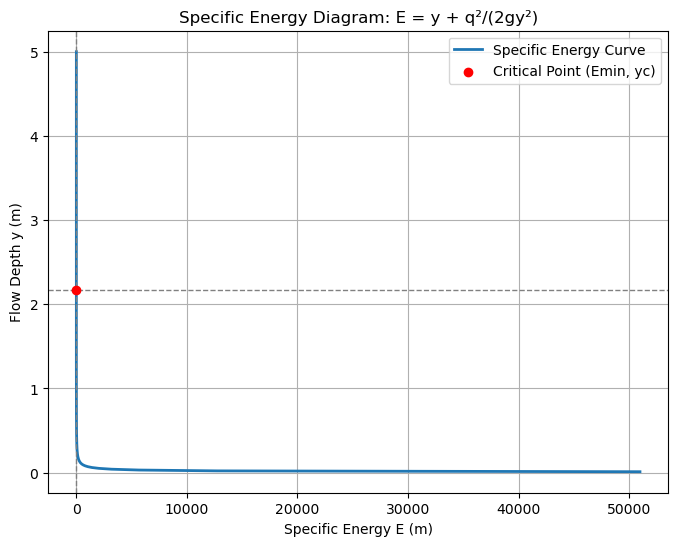

In [1]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81      
q = 10      

y = np.linspace(0.01, 5, 500)

# Specific Energy equation: E = y + q^2 / (2 g y^2)
E = y + q**2 / (2 * g * y**2)

# Compute critical depth yc = (q^2/g)^(1/3)
yc = (q**2 / g)**(1/3)
Emin = yc + q**2 / (2 * g * yc**2)

plt.figure(figsize=(8, 6))
plt.plot(E, y, linewidth=2, label="Specific Energy Curve")

plt.scatter(Emin, yc, color='red', zorder=5, label="Critical Point (Emin, yc)")
plt.axvline(Emin, linestyle='--', color='gray', linewidth=1)
plt.axhline(yc, linestyle='--', color='gray', linewidth=1)

plt.xlabel("Specific Energy E (m)")
plt.ylabel("Flow Depth y (m)")
plt.title("Specific Energy Diagram: E = y + q²/(2gy²)")
plt.legend()
plt.grid(True)

plt.show()

In [2]:
yc

2.1682548718200434

In [3]:
Emin

3.2523823077300653

Critical depth yc = 0.4671 m
Minimum specific energy Emin = 0.7007 m


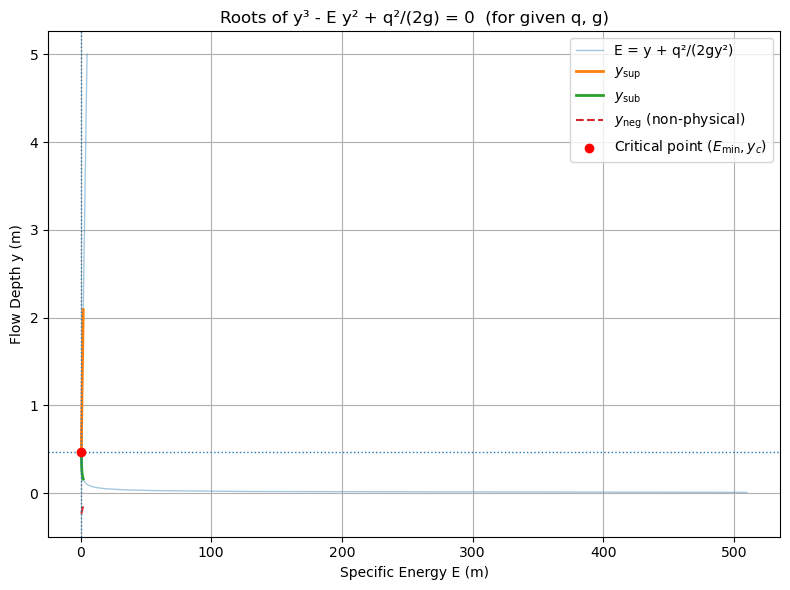

In [4]:
import numpy as np
import matplotlib.pyplot as plt

g = 9.81       
q = 1.0        

yc = (q**2 / g)**(1/3)                  
Emin = yc + q**2 / (2 * g * yc**2)      

print(f"Critical depth yc = {yc:.4f} m")
print(f"Minimum specific energy Emin = {Emin:.4f} m")

# 1) Original specific energy curve: E(y) = y + q^2/(2 g y^2)

y_vals = np.linspace(0.01, 5, 500)
E_vals_from_y = y_vals + q**2 / (2 * g * y_vals**2)

# 2) Solve cubic y^3 - E y^2 + (q^2 / 2g) = 0 for many E

E_vals = np.linspace(Emin, 3 * Emin, 400)  

y_sup_list = []
y_sub_list = []
y_neg_list = []

for E in E_vals:
    # Cubic: y^3 - E y^2 + (q^2 / 2g) = 0
    coeffs = [1.0, -E, 0.0, q**2 / (2 * g)]
    roots = np.roots(coeffs)

    real_roots = np.real(roots[np.isclose(roots.imag, 0, atol=1e-8)])
    real_roots.sort()   

    # Three real roots for E >= Emin.
    y_neg  = real_roots[0]   
    y_sub  = real_roots[1]   
    y_sup  = real_roots[2]   

    y_neg_list.append(y_neg)
    y_sub_list.append(y_sub)
    y_sup_list.append(y_sup)

plt.figure(figsize=(8, 6))

plt.plot(E_vals_from_y, y_vals, linewidth=1, alpha=0.4, label="E = y + q²/(2gy²)")

plt.plot(E_vals, y_sup_list, linewidth=2, label=r"$y_{\mathrm{sup}}$")
plt.plot(E_vals, y_sub_list, linewidth=2, label=r"$y_{\mathrm{sub}}$")
plt.plot(E_vals, y_neg_list, linestyle='--', linewidth=1.5, label=r"$y_{\mathrm{neg}}$ (non-physical)")

plt.scatter(Emin, yc, color='red', zorder=5, label="Critical point $(E_{\min}, y_c)$")
plt.axvline(Emin, linestyle=':', linewidth=1)
plt.axhline(yc, linestyle=':', linewidth=1)

plt.xlabel("Specific Energy E (m)")
plt.ylabel("Flow Depth y (m)")
plt.title("Roots of y³ - E y² + q²/(2g) = 0  (for given q, g)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()